    # Oficina de Machine Learning | Regressão: quanto vai custar cada cliente?

**Prof. Mateus Henrique Zeiser**
ABEX VI: Projeto Integrado III | Aula 12 (29/10/2026) | Sistemas de Informação

    ## Objetivo
    Na aula 11, a regressão linear do gasto da FluxoPlay foi calculada à mão com 8 clientes. Aqui o mesmo fluxo é feito em código, com uma base **real**: estimar o custo anual de saúde de cada beneficiário de um plano, para apoiar a precificação. Depois, o grupo adapta este notebook à base do próprio projeto (seção 11), quando o alvo do projeto for um **número**.

    ## Base de dados
    Medical Insurance Cost, base pública (livro *Machine Learning with R*, B. Lantz; também no Kaggle). 1.338 beneficiários; cada linha é uma pessoa.

    | Variável | Descrição |
    |---|---|
    | `age` | Idade |
    | `sex` | Sexo (female/male) |
    | `bmi` | Índice de massa corporal (IMC) |
    | `children` | Número de dependentes |
    | `smoker` | Fumante (yes/no) |
    | `region` | Região dos EUA |
    | `charges` | Custo anual em USD: o **alvo** |

## Roteiro
| Seção | Etapa | Pergunta | Etapa da aula 11 |
|---|---|---|---|
| 0 | Configuração e carregamento | De onde vêm os dados e o que se quer prever? | 1. Problema |
| 1 | Auditoria inicial da base | Há problemas de tipo, ausência, duplicata ou consistência? | 2. Dados |
| 2 | Divisão treino e teste | Como separar os dados antes de tomar decisões? | 5. Treino e teste |
| 3 | EDA inicial (no treino) | O que os dados mostram sobre o alvo? | 3. Variáveis |
| 4 | Pré-processamento | O que precisa ser transformado, e por quê? | 4. Preparação |
| 5 | EDA de validação | O pré-processamento fez o que deveria? Há vazamento? | 4. Preparação |
| 6 | Modelagem | Qual modelo e qual complexidade generalizam melhor? | 6. Treinamento |
| 7 | Avaliação final no teste | Qual o desempenho em dados nunca vistos? | 7. Previsões e 8. Avaliação |
| 8 | Análise de erros e interpretação | Onde o modelo erra e o que ele aprendeu? | 9. Interpretação |
| 9 | Conclusões | | |
| 10 | Desafios | | |
| 11 | Entrega: adaptação ao projeto do grupo | | |

Sequência correta vista em aula: (1) limpar o que é regra fixa, (2) separar treino e teste, (3) ajustar as transformações só no treino, (4) escolher o modelo sem olhar o teste, (5) usar o teste uma única vez.

## Como este notebook será usado no projeto

O notebook está pronto e roda do início ao fim com a base de exemplo. Na seção 11, o grupo faz uma cópia e o adapta à base do projeto. O código das seções 2 a 8 não precisa ser reescrito: ele funciona com qualquer base em que uma linha é uma observação e uma coluna é o alvo.

| Onde | O que o grupo modifica |
|---|---|
| 0. Parâmetros | arquivo, alvo,  colunas que ficam fora do modelo, custos |
| 1.3 Função `limpar` | as regras fixas de limpeza da base do projeto |
| 4.1 Função `criar_atributos` | as novas variáveis que fazem sentido no projeto (ou nenhuma) |
| Células de texto marcadas com **Leitura** | reescritas com o que os dados do projeto mostram |
| 3.8 e 9 | tabela de achados e decisões e conclusões do projeto |

# 0. Configuração e carregamento

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
sns.set_style('whitegrid')
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

## Parâmetros do problema

Esta é a célula que muda quando o notebook é usado em outra base. O **alvo** precisa ser numérico. `COLUNAS_FORA` recebe identificadores e colunas que só existem depois do que se quer prever.

In [2]:
URL = 'https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv'
ALVO = 'charges'               # coluna numérica que se quer prever
COLUNAS_FORA = []              # identificadores e colunas que só existem depois do evento
PROPORCAO_TESTE = 0.25         # parte da base guardada para a avaliação final
SEED = 42

In [3]:
# Upload de arquivo no Google Colab (opcional).
# Por padrão o notebook baixa a base pública pela internet.
# Para usar um arquivo seu, descomente as três linhas abaixo, rode a célula e escolha o arquivo.

# from google.colab import files
# enviados = files.upload()
# ARQUIVO_LOCAL = list(enviados.keys())[0]

ARQUIVO_LOCAL = globals().get('ARQUIVO_LOCAL', None)
print('Arquivo local:', ARQUIVO_LOCAL if ARQUIVO_LOCAL else 'nenhum, será usada a base pública')

Arquivo local: nenhum, será usada a base pública


In [4]:
df_bruto = pd.read_csv(ARQUIVO_LOCAL if ARQUIVO_LOCAL else URL, sep=None, engine='python')   # para .xlsx: pd.read_excel(ARQUIVO_LOCAL)
print('Shape:', df_bruto.shape)
df_bruto.head()

Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,"16,884.924"
1,18,male,33.770,1,no,southeast,"1,725.552"
2,28,male,33.000,3,no,southeast,"4,449.462"
3,33,male,22.705,0,no,northwest,"21,984.471"
4,32,male,28.880,0,no,northwest,"3,866.855"


# 1. Auditoria inicial da base

## 1.1 Estrutura e tipos de atributo

In [5]:
df_bruto.info()
pd.DataFrame({'dtype': df_bruto.dtypes.astype(str), 'distintos': df_bruto.nunique(),
              'exemplo': [df_bruto[c].dropna().iloc[0] for c in df_bruto.columns]})

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


,dtype,distintos,exemplo
age,int64,47,19
sex,str,2,female
bmi,float64,548,27.900
children,int64,6,0
smoker,str,2,yes
region,str,4,southwest
charges,float64,1337,"16,884.924"


**Leitura.** As sete colunas já chegam com o tipo certo: três numéricas (`age`, `bmi`, `children`), três categóricas (`sex`, `smoker`, `region`) e o alvo numérico `charges`. Não há identificador. `children` é numérica discreta (0 a 5).

## 1.2 Qualidade dos dados

| Dimensão | Verificação |
|---|---|
| Completude | NaN e ausentes disfarçados (texto vazio, `?`, `NA`) |
| Unicidade | Linhas repetidas |
| Validade | Faixas plausíveis para idade, IMC, dependentes e custo |
| Consistência | Categorias escritas de formas diferentes |

In [6]:
# Completude: NaN e ausentes "disfarçados" (texto vazio, '?', 'NA'...), que o pandas não reconhece.
disfarcados = ['', ' ', '?', 'na', 'n/a', 'nan', 'none', 'null', '-']
tab_ausentes = pd.DataFrame({
    'NaN': df_bruto.isnull().sum(),
    '% NaN': (100 * df_bruto.isnull().mean()).round(2),
    'disfarçados': [df_bruto[c].astype(str).str.strip().str.lower().isin(disfarcados).sum()
                    if not pd.api.types.is_numeric_dtype(df_bruto[c]) else 0 for c in df_bruto.columns],
})
display(tab_ausentes)
print('Linhas duplicadas (iguais em todas as colunas):', df_bruto.duplicated().sum())

,NaN,% NaN,disfarçados
age,0,0.000,0
sex,0,0.000,0
bmi,0,0.000,0
children,0,0.000,0
smoker,0,0.000,0
region,0,0.000,0
charges,0,0.000,0


Linhas duplicadas (iguais em todas as colunas): 1


In [7]:
texto = df_bruto.select_dtypes(exclude='number').drop(columns=COLUNAS_FORA + [ALVO], errors='ignore')
for c in texto.columns:
    print(f'{c:<10}', sorted(texto[c].astype(str).unique()))
# Específico da base de exemplo: no projeto, adapte as faixas de validade às colunas da base.
regras = {'age entre 18 e 100': ~df_bruto['age'].between(18, 100), 'bmi entre 10 e 70': ~df_bruto['bmi'].between(10, 70),
          'children entre 0 e 10': ~df_bruto['children'].between(0, 10), 'charges > 0': ~(df_bruto['charges'] > 0)}
display(pd.DataFrame({'violações': {k: int(v.sum()) for k, v in regras.items()}}))
display(df_bruto[df_bruto.duplicated(keep=False)])

sex        ['female', 'male']
smoker     ['no', 'yes']
region     ['northeast', 'northwest', 'southeast', 'southwest']


,violações
age entre 18 e 100,0
bmi entre 10 e 70,0
children entre 0 e 10,0
charges > 0,0


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.590,0,no,northwest,"1,639.563"
581,19,male,30.590,0,no,northwest,"1,639.563"


**Leitura.** Não há ausentes, os valores estão em faixas plausíveis e as categorias são consistentes. Há **uma linha repetida** (homem de 19 anos, mesmo IMC, mesma região e mesmo custo, até os centavos): é tratada como registro duplicado e sai na limpeza.

## 1.3 Limpeza determinística

Só entram aqui **regras fixas**, que não dependem de estatísticas dos dados e por isso podem ser aplicadas antes de separar treino e teste.

In [8]:
def limpar(d):
    d = d.copy()
    # Regras gerais (servem para qualquer base): texto sem espaços nas pontas e vazio como ausente.
    for c in d.select_dtypes(exclude='number').columns:
        d[c] = d[c].astype(str).str.strip().replace({'': np.nan, 'nan': np.nan, 'None': np.nan})
    d = d.drop_duplicates()
    # Regras desta base (no projeto, reescreva este bloco):
    d = d[d[ALVO].notna()]
    return d

df = limpar(df_bruto)
y = df[ALVO]
X = df.drop(columns=[ALVO] + COLUNAS_FORA)
print(f'Linhas: {len(df_bruto)} -> {len(df)} | features: {X.shape[1]}')
print('Ausentes depois da limpeza:', int(X.isnull().sum().sum()))

Linhas: 1338 -> 1337 | features: 6
Ausentes depois da limpeza: 0


# 2. Divisão treino e teste

O teste fica "trancado na gaveta" (aula 11) até a seção 7.

In [9]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=PROPORCAO_TESTE, random_state=SEED)
print(f'Treino: {len(X_treino)} linhas | Teste: {len(X_teste)} linhas')
pd.DataFrame({'treino': y_treino.describe(), 'teste': y_teste.describe()}).round(1)

Treino: 1002 linhas | Teste: 335 linhas


,treino,teste
count,"1,002.000",335.000
mean,"13,082.300","13,867.800"
std,"11,735.500","13,169.200"
min,"1,121.900","1,131.500"
25%,"4,755.800","4,674.500"
50%,"9,285.800","9,567.000"
75%,"16,746.700","16,437.800"
max,"62,592.900","63,770.400"


# 3. EDA inicial (no treino)

## 3.1 Variável alvo e modelo de referência

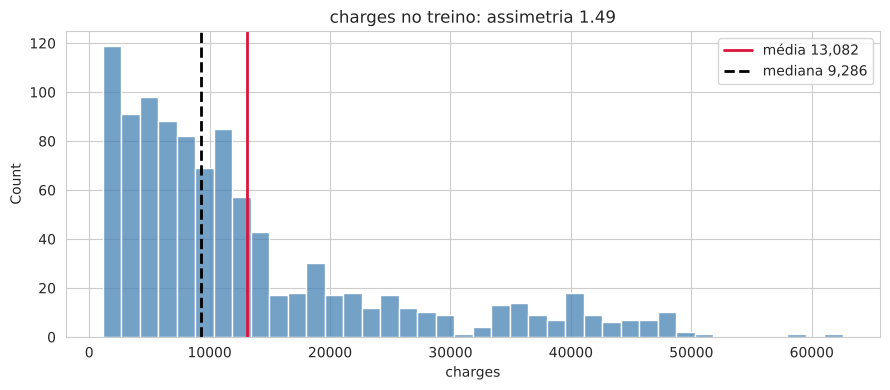

Referência: prever sempre a média do treino (13,082) erra em média 8,847 (MAE no próprio treino).


In [10]:
eda = X_treino.assign(alvo=y_treino.values)
NUM = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
CAT = [c for c in X.columns if c not in NUM]
plt.figure(figsize=(9, 4))
sns.histplot(y_treino, bins=40, color='steelblue')
plt.axvline(y_treino.mean(), color='crimson', lw=2, label=f'média {y_treino.mean():,.0f}')
plt.axvline(y_treino.median(), color='black', ls='--', lw=2, label=f'mediana {y_treino.median():,.0f}')
plt.title(f'{ALVO} no treino: assimetria {y_treino.skew():.2f}')
plt.legend()
plt.tight_layout()
plt.show()
erro_ref = mean_absolute_error(y_treino, np.full(len(y_treino), y_treino.mean()))
print(f'Referência: prever sempre a média do treino ({y_treino.mean():,.0f}) erra em média {erro_ref:,.0f} (MAE no próprio treino).')

**Leitura.** O custo tem **assimetria forte à direita** (1,49): a maioria custa menos de 15 mil USD por ano, e uma minoria custa de 30 a 60 mil. Por isso a média (13.082) fica bem acima da mediana (9.286). Prever sempre a média erra, em média, 8.847 USD: esse é o erro que qualquer modelo precisa reduzir.

## 3.2 Variáveis numéricas

,n,média,mediana,desvio padrão,mín,Q1,Q3,máx,IQR,assimetria,outliers (IQR),% outliers
age,"1,002.000",39.050,39.000,13.970,18.000,27.000,51.000,64.000,24.000,0.080,0.000,0.000
bmi,"1,002.000",30.610,30.210,6.010,15.960,26.320,34.600,53.130,8.280,0.320,6.000,0.600
children,"1,002.000",1.090,1.000,1.200,0.000,0.000,2.000,5.000,2.000,0.950,0.000,0.000


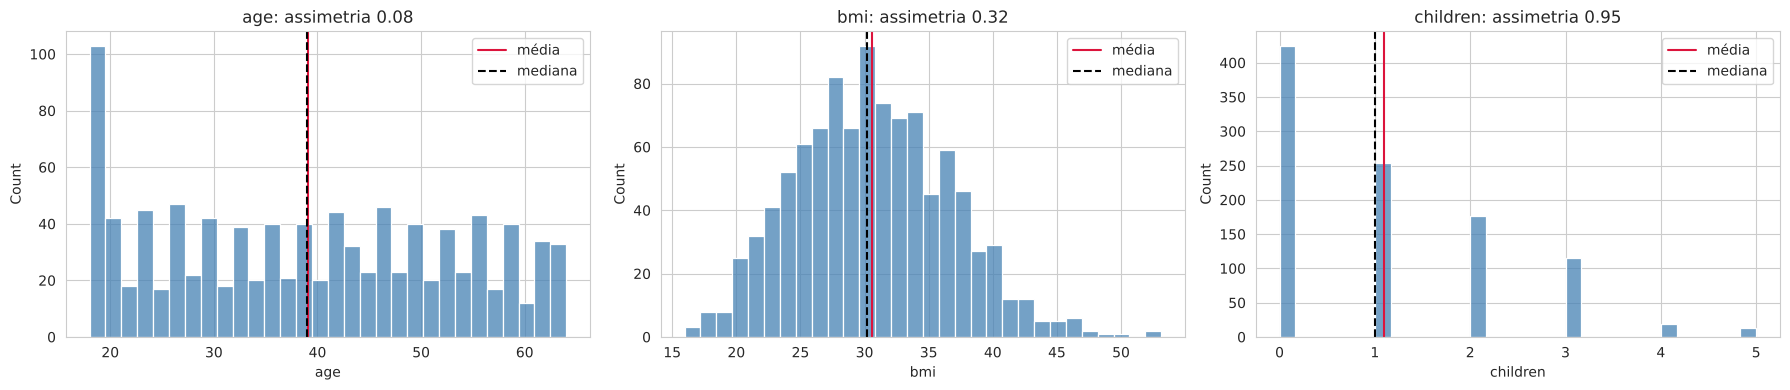

In [11]:
def resumo_numerico(dados):
    # Centro, dispersão, forma e extremos (medidas vistas na aula de EDA).
    linhas = {}
    for c in dados.columns:
        x = dados[c].dropna()
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        n_out = int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum())
        linhas[c] = {'n': len(x), 'média': x.mean(), 'mediana': x.median(), 'desvio padrão': x.std(),
                     'mín': x.min(), 'Q1': q1, 'Q3': q3, 'máx': x.max(), 'IQR': iqr,
                     'assimetria': x.skew(), 'outliers (IQR)': n_out, '% outliers': 100 * n_out / len(x)}
    return pd.DataFrame(linhas).T

def outliers_iqr(x):
    # Regra do boxplot: fora de [Q1 - 1,5*IQR ; Q3 + 1,5*IQR]
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)

def outliers_desvio(x, k=3):
    # Regra do desvio padrão: mais de k desvios da média (z-score)
    return ((x - x.mean()) / x.std()).abs() > k


display(resumo_numerico(eda[NUM]).round(2))
fig, axes = plt.subplots(1, len(NUM), figsize=(6 * len(NUM), 4), squeeze=False)
for ax, c in zip(axes[0], NUM):
    sns.histplot(eda[c].dropna(), bins=30, ax=ax, color='steelblue')
    ax.axvline(eda[c].mean(), color='crimson', lw=1.5, label='média')
    ax.axvline(eda[c].median(), color='black', ls='--', lw=1.5, label='mediana')
    ax.set_title(f'{c}: assimetria {eda[c].skew():.2f}')
    ax.legend()
plt.tight_layout()
plt.show()

**Leitura.** - `age` se espalha de forma quase uniforme entre 18 e 64 anos.
- `bmi` é quase simétrico, com média perto de 30 (o limite de obesidade da OMS): metade dos beneficiários é obesa.
- `children` é discreta: 42% não têm dependentes, e 4 ou 5 dependentes são raros.

## 3.3 Variáveis categóricas

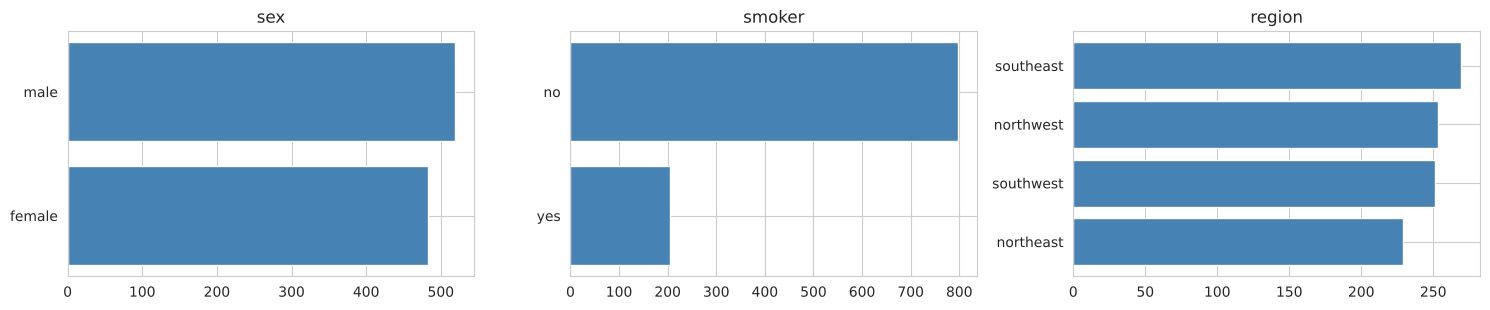

In [12]:
fig, axes = plt.subplots(1, len(CAT), figsize=(5 * len(CAT), 3.2), squeeze=False)
for ax, c in zip(axes[0], CAT):
    freq = eda[c].value_counts().head(10)
    ax.barh(freq.index.astype(str)[::-1], freq.values[::-1], color='steelblue')
    ax.set_title(c)
plt.tight_layout()
plt.show()

**Leitura.** Cerca de 20% são fumantes. Sexo e região estão equilibrados (cada região tem de 23% a 27% dos beneficiários). Não há categorias raras.

## 3.4 Outliers: erro ou caso real?

In [13]:
display(pd.DataFrame({'outliers (IQR)': {c: int(outliers_iqr(eda[c].dropna()).sum()) for c in NUM + ['alvo']},
                      'outliers (|z| > 3)': {c: int(outliers_desvio(eda[c].dropna()).sum()) for c in NUM + ['alvo']}}))
fora = outliers_iqr(eda['alvo'])
print(f'Outliers do alvo: {fora.sum()} linhas. Perfil deles x demais:')
perfil = {f'média de {c}': (eda.loc[fora, c].mean(), eda.loc[~fora, c].mean()) for c in NUM}
for c in CAT:
    for v in sorted(eda[c].dropna().unique()):
        perfil[f'% {c} = {v}'] = (100 * (eda.loc[fora, c] == v).mean(), 100 * (eda.loc[~fora, c] == v).mean())
pd.DataFrame(perfil, index=['outliers do alvo', 'demais']).T.round(1)

,outliers (IQR),outliers (|z| > 3)
age,0,0
bmi,6,4
children,0,13
alvo,96,8


Outliers do alvo: 96 linhas. Perfil deles x demais:


,outliers do alvo,demais
média de age,40.400,38.900
média de bmi,35.200,30.100
média de children,1.300,1.100
% sex = female,35.400,49.600
% sex = male,64.600,50.400
% smoker = no,3.100,87.600
% smoker = yes,96.900,12.400
% region = northeast,19.800,23.200
% region = northwest,12.500,26.600
% region = southeast,39.600,25.500


**Leitura.** Os 96 outliers do custo (pela regra do IQR) **não são erros**: 97% deles são fumantes (contra 12% nos demais), com IMC médio de 35. São os clientes caros que o modelo mais precisa acertar, e por isso ficam na base. Os 6 outliers de `bmi` (valores perto de 50) também são plausíveis.

## 3.5 Numéricas e o alvo

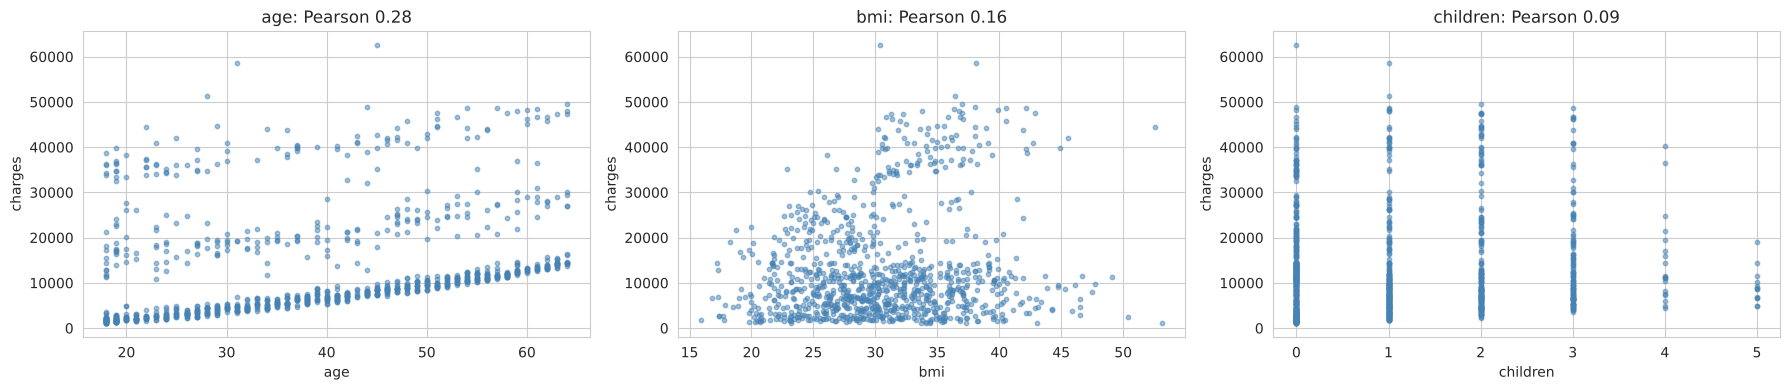

In [14]:
fig, axes = plt.subplots(1, len(NUM), figsize=(6 * len(NUM), 4), squeeze=False)
for ax, c in zip(axes[0], NUM):
    ax.scatter(eda[c], eda['alvo'], s=10, alpha=0.5, color='steelblue')
    ax.set(xlabel=c, ylabel=ALVO, title=f'{c}: Pearson {eda[c].corr(eda["alvo"]):.2f}')
plt.tight_layout()
plt.show()

**Leitura.** A idade tem a maior correlação com o custo (0,28), mas o gráfico mostra o que a correlação esconde: **três faixas paralelas**, todas subindo com a idade. A idade explica a subida dentro de cada faixa; outra variável explica em que faixa a pessoa está. `bmi` e `children` têm correlação fraca.

## 3.6 Categóricas e o alvo: média por categoria

Para cada categoria, a média do alvo. A **amplitude** (maior média menos menor média, entre categorias com pelo menos 30 linhas) ordena as variáveis pelo quanto separam valores altos e baixos do alvo.

,amplitude da média
smoker,"22,579.000"
region,"2,204.000"
sex,"1,380.000"


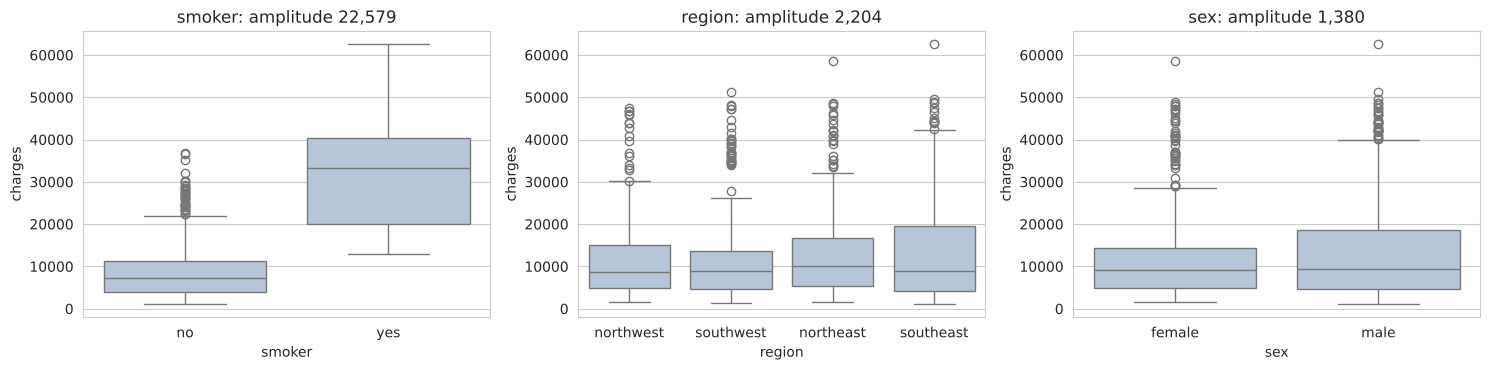

In [15]:
def media_por(col):
    return eda.groupby(col, observed=True)['alvo'].agg(n='count', media='mean', mediana='median').sort_values('media')

amplitude = pd.Series({c: media_por(c).query('n >= 30')['media'].agg(lambda s: s.max() - s.min()) for c in CAT}).sort_values(ascending=False)
display(amplitude.round(0).to_frame('amplitude da média'))
fig, axes = plt.subplots(1, len(CAT), figsize=(5 * len(CAT), 3.8), squeeze=False)
for ax, c in zip(axes[0], amplitude.index):
    sns.boxplot(data=eda, x=c, y='alvo', ax=ax, color='lightsteelblue', order=media_por(c).index)
    ax.set(title=f'{c}: amplitude {amplitude[c]:,.0f}', ylabel=ALVO)
plt.tight_layout()
plt.show()

**Leitura.** `smoker` é, de longe, a variável que mais separa: fumantes custam em média 31 mil USD por ano, contra 8,5 mil dos não fumantes (amplitude de 22,6 mil). Região (2,2 mil) e sexo (1,4 mil) quase não diferenciam o custo.

## 3.7 Relações entre variáveis e discretização

Pearson entre as numéricas e, para a numérica mais correlacionada com o alvo, a média do alvo por faixa (`pd.qcut`, quatro faixas de mesmo tamanho), separada pela categórica de maior amplitude: uma forma simples de ver se o efeito de uma variável depende de outra.

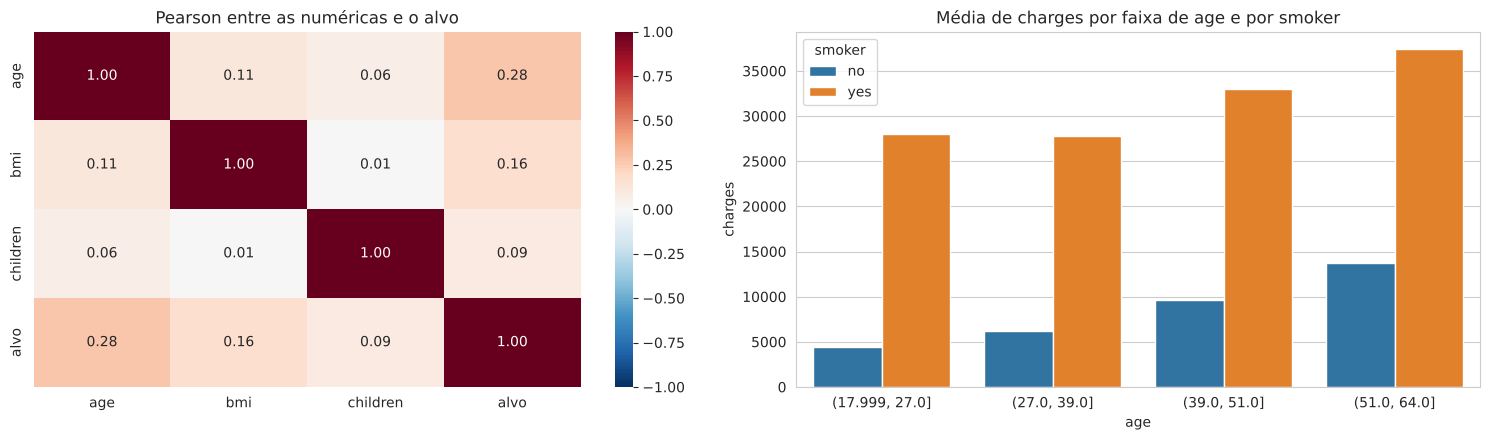

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(eda[NUM + ['alvo']].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Pearson entre as numéricas e o alvo')
principal = eda[NUM].corrwith(eda['alvo']).abs().idxmax()
grupo = amplitude.index[0]
faixas = pd.qcut(eda[principal], 4, duplicates='drop')
sns.barplot(data=eda.assign(faixa=faixas.astype(str)).dropna(subset=[principal]), x='faixa', y='alvo', hue=grupo,
            ax=axes[1], errorbar=None, order=[str(c) for c in faixas.cat.categories])
axes[1].set(title=f'Média de {ALVO} por faixa de {principal} e por {grupo}', xlabel=principal, ylabel=ALVO)
plt.tight_layout()
plt.show()

**Leitura.** - As numéricas quase não se correlacionam entre si (no máximo 0,11): não há redundância.
- Em todas as faixas de idade, fumantes custam muito mais, e o custo sobe com a idade nos dois grupos: os efeitos de idade e fumo se **somam**. As três faixas de 3.5 são não fumantes, fumantes com IMC abaixo de 30 e fumantes obesos (IMC de 30 ou mais).

    ## 3.8 Síntese: achados e decisões

| Achado | Evidência | Decisão |
|---|---|---|
| Uma linha repetida | 1.2 | `limpar`: retirar duplicatas |
| Alvo muito assimétrico, outliers reais (fumantes) | 3.1, 3.4 | manter as linhas; olhar MAE e RMSE |
| `smoker` separa o custo mais que qualquer outra variável | 3.6 | manter, com one-hot |
| Custo sobe com a idade em todos os grupos | 3.5, 3.7 | manter `age` como numérica |
| Três faixas: não fumante, fumante, fumante obeso | 3.5, 3.7 | criar `obeso` e `fumante_obeso` (4.1) |
| Região e sexo quase não diferenciam | 3.6 | manter; o modelo mostrará o peso delas |

# 4. Pré-processamento

## 4.1 Engenharia de atributos

Novas variáveis criadas com **regras fixas** (sem estatísticas dos dados), aplicadas igualmente a treino e teste. No projeto, troque por regras que façam sentido ou deixe a função só com `return X.copy()`.

In [17]:
def criar_atributos(X):
    X = X.copy()
    X['obeso'] = np.where(X['bmi'] >= 30, 'yes', 'no')                                    # critério da OMS: IMC >= 30
    X['fumante_obeso'] = np.where((X['smoker'] == 'yes') & (X['bmi'] >= 30), 'yes', 'no')  # combinação de dois riscos
    return X

X_treino = criar_atributos(X_treino)
X_teste = criar_atributos(X_teste)
NUM = [c for c in X_treino.columns if pd.api.types.is_numeric_dtype(X_treino[c])]
CAT = [c for c in X_treino.columns if c not in NUM]
print('Numéricas:', NUM)
print('Categóricas:', CAT)

Numéricas: ['age', 'bmi', 'children']
Categóricas: ['sex', 'smoker', 'region', 'obeso', 'fumante_obeso']


## 4.2 Pipeline de preparação

| Grupo | Passos | Por quê (aula 11) |
|---|---|---|
| Numéricas | faltantes preenchidos pela **mediana do treino** | a mediana é calculada só com o treino e aplicada ao teste |
| Categóricas | faltante vira a categoria `ausente`; one-hot com a **primeira categoria como referência** | a regressão linear precisa de números; com a referência, cada coeficiente compara a categoria com ela |

Nem a árvore nem a regressão linear precisam de padronização aqui: a árvore compara cada variável com um corte, e a regressão linear sem regularização chega às mesmas previsões com ou sem z-score. Sem padronizar, os coeficientes ficam na unidade original (USD por ano de idade, por exemplo).

In [18]:
def criar_preparo():
    return ColumnTransformer([
        ('numericas', SimpleImputer(strategy='median'), NUM),
        ('categoricas', Pipeline([('ausente', SimpleImputer(strategy='constant', fill_value='ausente')),
                                  ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))]), CAT)],
        verbose_feature_names_out=False)

def transformar(prep, dados):
    return pd.DataFrame(prep.transform(dados), columns=prep.get_feature_names_out(), index=dados.index)

preparo = criar_preparo().fit(X_treino)
Xtr_p, Xte_p = transformar(preparo, X_treino), transformar(preparo, X_teste)
print(f'{X_treino.shape[1]} colunas originais -> {Xtr_p.shape[1]} colunas depois do one-hot')
Xtr_p.head()

8 colunas originais -> 10 colunas depois do one-hot


,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,obeso_yes,fumante_obeso_yes
763,27.000,26.030,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000
1079,63.000,33.660,3.000,1.000,0.000,0.000,1.000,0.000,1.000,0.000
178,46.000,28.900,2.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000
287,63.000,26.220,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000
1290,38.000,19.950,2.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


# 5. EDA de validação

## 5.1 Integridade

In [19]:
checks = {
    'sem ausentes depois da preparação': int(Xtr_p.isnull().sum().sum() + Xte_p.isnull().sum().sum()) == 0,
    'treino e teste com as mesmas colunas': list(Xtr_p.columns) == list(Xte_p.columns),
    'treino e teste sem linhas em comum': len(set(X_treino.index) & set(X_teste.index)) == 0,
    'alvo e colunas excluídas fora das features': not any(c in X_treino.columns for c in [ALVO] + COLUNAS_FORA),
    'one-hot: no máximo uma coluna ativa por variável': all(Xtr_p[[k for k in Xtr_p.columns if k.startswith(c + '_')]].sum(axis=1).max() <= 1 for c in CAT),
}
pd.DataFrame({'resultado': {k: 'OK' if v else 'FALHOU' for k, v in checks.items()}})

,resultado
sem ausentes depois da preparação,OK
treino e teste com as mesmas colunas,OK
treino e teste sem linhas em comum,OK
alvo e colunas excluídas fora das features,OK
one-hot: no máximo uma coluna ativa por variável,OK


## 5.2 Treino e teste continuam comparáveis?

In [20]:
display(pd.DataFrame({'média treino': X_treino[NUM].mean(), 'média teste': X_teste[NUM].mean(),
                      'mediana treino': X_treino[NUM].median(), 'mediana teste': X_teste[NUM].median()}).round(2))
print(f'Alvo: média treino {y_treino.mean():,.0f} | média teste {y_teste.mean():,.0f}')
c = amplitude.index[0]
pd.DataFrame({'treino': X_treino[c].value_counts(normalize=True), 'teste': X_teste[c].value_counts(normalize=True)}).round(3)

,média treino,média teste,mediana treino,mediana teste
age,39.050,39.740,39.000,41.000
bmi,30.610,30.810,30.210,30.780
children,1.090,1.110,1.000,1.000


Alvo: média treino 13,082 | média teste 13,868


,treino,teste
smoker,,
no,0.795,0.794
yes,0.205,0.206


## 5.3 Verificação de vazamento

Pergunta da aula 11 para cada feature: *eu saberia este valor no momento da previsão?* Uma verificação prática: treinar uma árvore com **uma feature de cada vez** e medir o erro. Se uma única coluna prevê o alvo quase sem erro, ela provavelmente carrega informação do próprio alvo.

Para mostrar como o vazamento aparece, a célula acrescenta, numa cópia dos dados, uma coluna fictícia `valor_reembolsado`: o valor que o plano reembolsou no fim do ano, conhecido só **depois** do custo.

In [21]:
def erro_uma_feature(Xa, ya, Xb, yb, coluna):
    cols_num = [coluna] if pd.api.types.is_numeric_dtype(Xa[coluna]) else []
    prep = ColumnTransformer([('n', SimpleImputer(strategy='median'), cols_num),
                              ('c', Pipeline([('a', SimpleImputer(strategy='constant', fill_value='ausente')),
                                              ('o', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), [coluna] if not cols_num else [])])
    m = Pipeline([('p', prep), ('m', DecisionTreeRegressor(max_depth=4, min_samples_leaf=20, random_state=SEED))]).fit(Xa[[coluna]], ya)
    return mean_absolute_error(yb, m.predict(Xb[[coluna]]))

# treino dividido em duas partes para não usar o teste
Xa, Xb, ya, yb = train_test_split(X_treino, y_treino, test_size=0.3, random_state=SEED)
rng = np.random.default_rng(SEED)
Xa_demo = Xa.assign(valor_reembolsado=(0.8 * ya * rng.uniform(0.95, 1.05, len(ya))).round(2))
Xb_demo = Xb.assign(valor_reembolsado=(0.8 * yb * rng.uniform(0.95, 1.05, len(yb))).round(2))

referencia = mean_absolute_error(yb, np.full(len(yb), ya.mean()))
vaz = pd.Series({c: erro_uma_feature(Xa_demo, ya, Xb_demo, yb, c) for c in list(X_treino.columns) + ['valor_reembolsado']})
vaz = vaz.sort_values().to_frame('MAE só com esta feature')
vaz['% do erro da referência'] = (100 * vaz.iloc[:, 0] / referencia).round(1)
vaz['alerta'] = np.where(vaz['% do erro da referência'] <= 20, 'POSSÍVEL VAZAMENTO', '')
print(f'Referência (média): MAE {referencia:,.0f}')
display(vaz)

Referência (média): MAE 9,019


,MAE só com esta feature,% do erro da referência,alerta
valor_reembolsado,827.127,9.200,POSSÍVEL VAZAMENTO
smoker,"5,775.768",64.000,
fumante_obeso,"5,888.994",65.300,
age,"8,864.402",98.300,
children,"9,014.327",99.900,
sex,"9,069.545",100.600,
region,"9,097.039",100.900,
obeso,"9,180.794",101.800,
bmi,"9,580.467",106.200,


**Leitura.** Nenhuma feature real chega perto de prever o custo sozinha: a melhor, `smoker`, ainda erra 64% do que erra a referência. Já a coluna fictícia `valor_reembolsado` erra só 9%: ela é calculada a partir do próprio custo, depois que ele acontece. No momento de precificar o plano, esse valor não existe. No projeto, qualquer feature com alerta precisa ser investigada antes de entrar no modelo.

## 5.4 Categoria nova e valor ausente: o pipeline está preparado?

In [22]:
novo = X_teste.head(2).copy()
num0, cat0 = NUM[0], 'region' if 'region' in CAT else CAT[0]
novo.loc[novo.index[0], num0] = np.nan
novo.loc[novo.index[1], cat0] = 'categoria que não existe no treino'
t = transformar(preparo, novo)
print(f'{num0} ausente -> preenchido com a mediana do treino: {t.iloc[0][num0]}')
print(f'Colunas de {cat0} para a categoria nova:', t.iloc[1][[k for k in t.columns if k.startswith(cat0 + "_")]].to_dict())

age ausente -> preenchido com a mediana do treino: 39.0
Colunas de region para a categoria nova: {'region_northwest': 0.0, 'region_southeast': 0.0, 'region_southwest': 0.0}


**Leitura.** O valor ausente recebe a mediana do treino (39 anos). A região desconhecida vira zeros nas três colunas de `region`, o que equivale à categoria de referência (`northeast`, retirada pelo `drop='first'`): o modelo não quebra, mas trata o cliente como se fosse do nordeste.

# 6. Modelagem

## 6.1 Protocolo e métricas

O teste continua guardado. Para comparar modelos e escolher a complexidade da árvore **sem olhar o teste**, o treino é dividido mais uma vez:

| Parte | Uso |
|---|---|
| **ajuste** (75% do treino) | treinar os modelos candidatos |
| **validação** (25% do treino) | comparar os candidatos e escolher o modelo |
| **teste** | usado uma única vez, na seção 7 |

| Métrica | Fórmula | Pergunta |
|---|---|---|
| MAE | média de \|real - previsto\| | Quanto o modelo erra, em média, na unidade do alvo? |
| RMSE | raiz da média de (real - previsto)² | Igual ao MAE, mas pesando mais os erros grandes |
| Redução | 1 - MAE do modelo / MAE da referência | Quanto o modelo melhora em relação a prever sempre a média? |

In [23]:
X_aj, X_val, y_aj, y_val = train_test_split(X_treino, y_treino, test_size=0.25, random_state=SEED)
print(f'Ajuste: {len(X_aj)} | Validação: {len(X_val)} | Teste (guardado): {len(X_teste)}')

def pipe(modelo):
    return Pipeline([('preparo', criar_preparo()), ('modelo', modelo)])

MIN_FOLHA = 10   # mínimo de clientes em cada folha (a regra de parada da aula 11)

def arvore(profundidade, min_folha=None):
    return pipe(DecisionTreeRegressor(max_depth=profundidade, min_samples_leaf=min_folha or MIN_FOLHA, random_state=SEED))

def metricas(y_real, prev, mae_ref=None):
    mae = mean_absolute_error(y_real, prev)
    r = {'MAE': mae, 'RMSE': np.sqrt(mean_squared_error(y_real, prev))}
    if mae_ref:
        r['redução do MAE'] = 1 - mae / mae_ref
    return r

Ajuste: 751 | Validação: 251 | Teste (guardado): 335


## 6.2 Referência, regra de uma pergunta e regressão linear

Três pontos de comparação: a **referência** (prever sempre a média do ajuste), a **melhor regra de uma pergunta** (uma árvore com profundidade 1, que prevê a média de cada lado) e a **regressão linear** da aula 11, agora com todas as features.

In [24]:
ref = pipe(DummyRegressor(strategy='mean')).fit(X_aj, y_aj)
mae_ref = mean_absolute_error(y_val, ref.predict(X_val))
regra = arvore(1).fit(X_aj, y_aj)
linear = pipe(LinearRegression()).fit(X_aj, y_aj)
print('Regra de uma pergunta:')
print(export_text(regra.named_steps['modelo'], feature_names=list(regra.named_steps['preparo'].get_feature_names_out()), decimals=1))
candidatos_val = {'referência (média)': ref, 'regra de uma pergunta': regra, 'regressão linear': linear}
pd.DataFrame({k: metricas(y_val, m.predict(X_val), mae_ref) for k, m in candidatos_val.items()}).T

Regra de uma pergunta:
|--- fumante_obeso_yes <= 0.5
|   |--- value: [9924.5]
|--- fumante_obeso_yes >  0.5
|   |--- value: [40841.0]



,MAE,RMSE,redução do MAE
referência (média),"9,139.085","12,143.336",0.000
regra de uma pergunta,"5,813.020","7,498.732",0.364
regressão linear,"2,622.340","4,832.202",0.713


In [25]:
coef = pd.Series(linear.named_steps['modelo'].coef_, index=linear.named_steps['preparo'].get_feature_names_out())
print(f'Intercepto: {linear.named_steps["modelo"].intercept_:,.0f}')
coef.sort_values(key=abs, ascending=False).round(0).to_frame('coeficiente (USD)')

Intercepto: -4,120


,coeficiente (USD)
fumante_obeso_yes,"19,924.000"
smoker_yes,"13,028.000"
region_southwest,"-1,200.000"
sex_male,-753.000
region_southeast,-742.000
obeso_yes,-673.000
children,592.000
age,255.000
bmi,100.000
region_northwest,82.000


**Leitura.** - A melhor regra de uma pergunta é "o cliente é fumante e obeso?": prevê 40.841 USD para quem é e 9.924 para quem não é. Só isso reduz o erro da referência em 36%.
- A regressão linear reduz o erro em 71% (MAE de 2.622 USD na validação). Os coeficientes estão em USD: ser fumante soma cerca de 13 mil por ano, e ser fumante **e** obeso soma mais 20 mil. Cada ano de idade soma cerca de 255 USD. `obeso` sozinho tem coeficiente pequeno: para não fumantes, o IMC quase não muda o custo.
- A variável criada na EDA (`fumante_obeso`) é a mais importante dos dois modelos.

## 6.3 Árvore de regressão com profundidade 3

A árvore de regressão faz as mesmas perguntas da árvore de classificação, mas cada folha prevê a **média do alvo** dos clientes que caem nela (`value`).

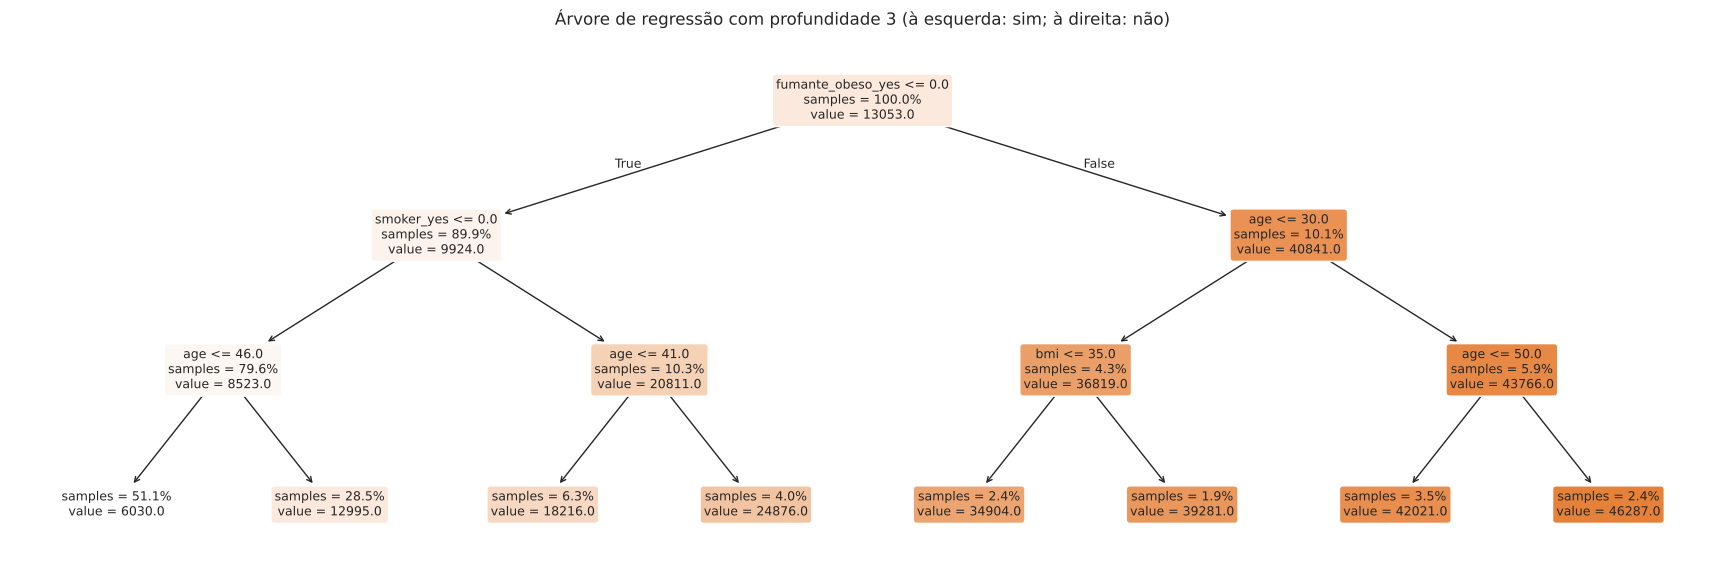

,MAE,RMSE
treino (ajuste),"2,990.243","4,692.482"
validação,"3,240.104","4,979.030"


In [26]:
arv3 = arvore(3).fit(X_aj, y_aj)
plt.figure(figsize=(22, 7))
plot_tree(arv3.named_steps['modelo'], feature_names=list(arv3.named_steps['preparo'].get_feature_names_out()), filled=True,
          rounded=True, proportion=True, impurity=False, fontsize=9, precision=0)
plt.title('Árvore de regressão com profundidade 3 (à esquerda: sim; à direita: não)')
plt.show()
pd.DataFrame({'treino (ajuste)': metricas(y_aj, arv3.predict(X_aj)), 'validação': metricas(y_val, arv3.predict(X_val))}).T

**Leitura.** A árvore faz as mesmas perguntas que a EDA sugeriu: primeiro fumante e obeso, depois fumante, depois idade. Cada folha prevê a média do grupo, de 6.030 USD (não fumantes até 46 anos) a 46.287 USD (fumantes obesos acima de 50). MAE de 2.990 no ajuste e 3.240 na validação: diferença pequena, sem sinal de overfitting.

## 6.4 Complexidade: underfitting e overfitting

Árvores de profundidade 1 a 15 e sem limite, com `min_samples_leaf=1` para deixar o efeito visível. MAE no ajuste e na validação (quanto menor, melhor).

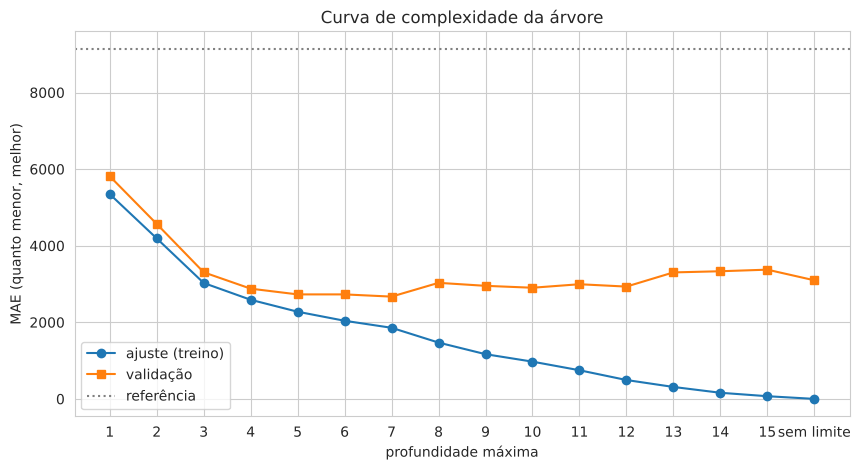

Profundidade com o menor MAE na validação: 7


,profundidade,folhas,MAE ajuste,MAE validação
0,1,2,"5,346.352","5,813.020"
2,3,8,"3,026.248","3,305.122"
6,7,91,"1,856.576","2,670.587"
9,10,293,972.426,"2,902.331"
15,sem limite,751,0.000,"3,096.627"


In [27]:
profundidades = list(range(1, 16)) + [None]
curva = []
for p in profundidades:
    m = arvore(p, min_folha=1).fit(X_aj, y_aj)
    curva.append({'profundidade': 'sem limite' if p is None else p, 'folhas': m.named_steps['modelo'].get_n_leaves(),
                  'MAE ajuste': mean_absolute_error(y_aj, m.predict(X_aj)), 'MAE validação': mean_absolute_error(y_val, m.predict(X_val))})
curva = pd.DataFrame(curva)
eixo = curva['profundidade'].astype(str)
plt.plot(eixo, curva['MAE ajuste'], 'o-', label='ajuste (treino)')
plt.plot(eixo, curva['MAE validação'], 's-', label='validação')
plt.axhline(mae_ref, color='gray', ls=':', label='referência')
plt.xlabel('profundidade máxima')
plt.ylabel('MAE (quanto menor, melhor)')
plt.title('Curva de complexidade da árvore')
plt.legend()
plt.show()

PROFUNDIDADE = int(curva.iloc[:-1].loc[curva.iloc[:-1]['MAE validação'].idxmin(), 'profundidade'])
print(f'Profundidade com o menor MAE na validação: {PROFUNDIDADE}')
display(curva.iloc[sorted({0, 2, PROFUNDIDADE - 1, 9, len(curva) - 1})])

# Desafio 1: descomente a linha abaixo para usar, daqui em diante, uma árvore sem limite.
# PROFUNDIDADE, MIN_FOLHA = None, 1

**Leitura.** A curva repete a aula 11. Com profundidade 1 e 2, o erro é alto nos dois conjuntos (underfitting). A validação melhora até a profundidade 7 (MAE de 2.671, com 91 folhas) e depois piora. Sem limite, a árvore tem uma folha por cliente (751): erro zero no ajuste e 3.097 na validação. Ela decorou o treino (overfitting).

## 6.5 Escolha do modelo na validação

In [28]:
candidatos_val[f'árvore (profundidade {PROFUNDIDADE or "sem limite"})'] = arvore(PROFUNDIDADE).fit(X_aj, y_aj)
comparacao = pd.DataFrame({k: metricas(y_val, m.predict(X_val), mae_ref) for k, m in candidatos_val.items()}).T.sort_values('MAE')
MODELO_ESCOLHIDO = comparacao.index[0]
display(comparacao)
print('Modelo escolhido pelo MAE na validação:', MODELO_ESCOLHIDO)

,MAE,RMSE,redução do MAE
regressão linear,"2,622.340","4,832.202",0.713
árvore (profundidade 7),"2,632.868","4,959.498",0.712
regra de uma pergunta,"5,813.020","7,498.732",0.364
referência (média),"9,139.085","12,143.336",0.000


Modelo escolhido pelo MAE na validação: regressão linear


**Leitura.** A regressão linear e a árvore de profundidade 7 empatam na validação (diferença de 10 USD no MAE). Com desempenho igual, vale o modelo mais simples e mais fácil de explicar: a regressão linear, cujos coeficientes estão em dólares.

# 7. Avaliação final no teste

Todos os candidatos são treinados com o **treino inteiro** (ajuste + validação) e avaliados uma única vez no teste. A escolha já foi feita na seção 6; a tabela de teste só confirma a estimativa.

,MAE,RMSE,redução do MAE
referência (média),"9,540.307","13,172.959",0.000
regra de uma pergunta,"5,351.183","6,966.390",0.439
regressão linear,"2,426.987","4,338.295",0.746
árvore (profundidade 7),"2,595.576","4,454.528",0.728


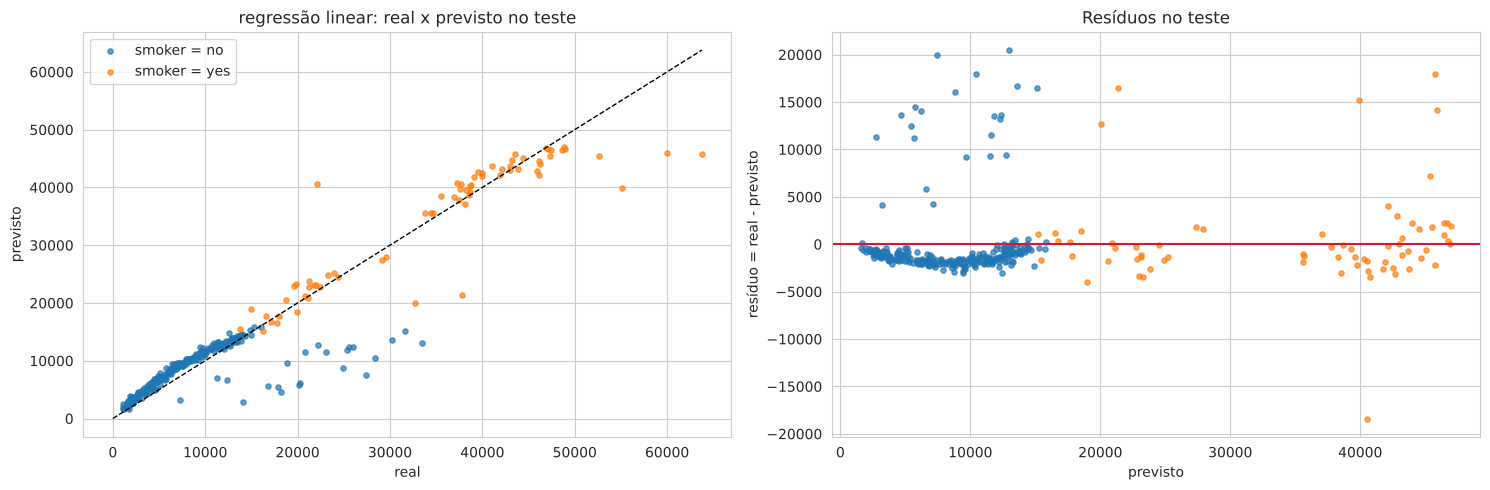

In [29]:
finais = {'referência (média)': pipe(DummyRegressor(strategy='mean')), 'regra de uma pergunta': arvore(1),
          'regressão linear': pipe(LinearRegression()), f'árvore (profundidade {PROFUNDIDADE or "sem limite"})': arvore(PROFUNDIDADE)}
finais = {k: m.fit(X_treino, y_treino) for k, m in finais.items()}
mae_ref_teste = mean_absolute_error(y_teste, finais['referência (média)'].predict(X_teste))
display(pd.DataFrame({k: metricas(y_teste, m.predict(X_teste), mae_ref_teste) for k, m in finais.items()}).T)

final = finais[MODELO_ESCOLHIDO]
prev_teste = final.predict(X_teste)
residuo = y_teste - prev_teste
grupo = amplitude.index[0]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for valor in X_teste[grupo].unique():
    sel = (X_teste[grupo] == valor).values
    axes[0].scatter(y_teste[sel], prev_teste[sel], s=14, alpha=0.7, label=f'{grupo} = {valor}')
    axes[1].scatter(prev_teste[sel], residuo[sel], s=14, alpha=0.7, label=f'{grupo} = {valor}')
lim = [0, max(y_teste.max(), prev_teste.max())]
axes[0].plot(lim, lim, 'k--', lw=1)
axes[0].set(xlabel='real', ylabel='previsto', title=f'{MODELO_ESCOLHIDO}: real x previsto no teste')
axes[1].axhline(0, color='crimson')
axes[1].set(xlabel='previsto', ylabel='resíduo = real - previsto', title='Resíduos no teste')
axes[0].legend()
plt.tight_layout()
plt.show()

**Leitura.** - No teste, a regressão linear erra em média 2.427 USD: 75% menos que a referência (9.540) e menos da metade da regra de uma pergunta (5.351). Os números ficam próximos dos da validação.
- Os pontos se concentram na diagonal para fumantes e para a maioria dos não fumantes. O problema está num grupo de **não fumantes com custo real muito acima do previsto** (resíduos de 10 a 20 mil USD): pessoas que tiveram algum gasto que as variáveis da base não explicam.
- Para os demais não fumantes, os resíduos ficam um pouco abaixo de zero: o modelo superestima levemente esse grupo, puxado pelos casos caros.

# 8. Análise de erros e interpretação

## 8.1 O que os modelos usam

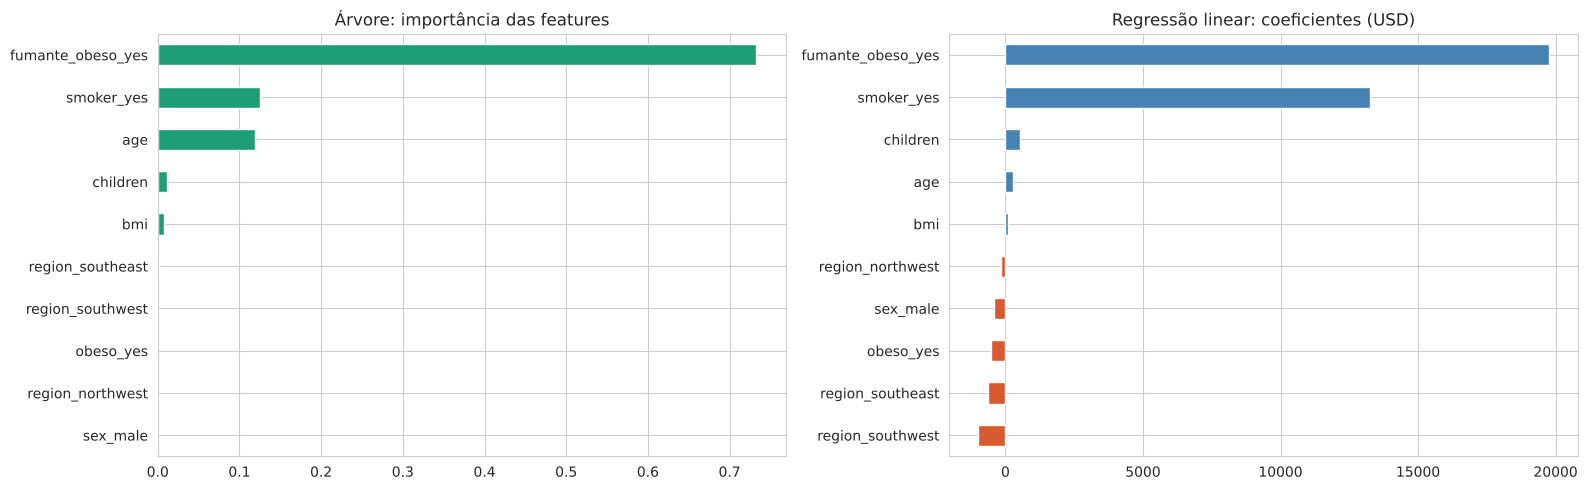

In [30]:
arv_final = finais[f'árvore (profundidade {PROFUNDIDADE or "sem limite"})']
imp = pd.Series(arv_final.named_steps['modelo'].feature_importances_, index=arv_final.named_steps['preparo'].get_feature_names_out())
coef = pd.Series(finais['regressão linear'].named_steps['modelo'].coef_, index=finais['regressão linear'].named_steps['preparo'].get_feature_names_out())
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
imp[imp > 0].sort_values().plot.barh(ax=axes[0], color='#1D9E75', title='Árvore: importância das features')
coef.sort_values().plot.barh(ax=axes[1], color=['#D85A30' if v < 0 else 'steelblue' for v in coef.sort_values()],
                             title='Regressão linear: coeficientes (USD)')
plt.tight_layout()
plt.show()

**Leitura.** Os dois modelos concordam: `fumante_obeso` e `smoker` dominam, seguidos pela idade. Na árvore, região e sexo não são usados; na regressão linear, seus coeficientes são pequenos (menos de 1.300 USD). Coeficientes e importâncias descrevem associações nesta base, não causas.

## 8.2 Onde o modelo erra

In [31]:
erros = X_teste.assign(real=y_teste.values, previsto=prev_teste.round(0), erro_absoluto=np.abs(residuo).round(0))
erros['erro %'] = (100 * erros['erro_absoluto'] / erros['real']).round(1)
for c in amplitude.index[:2]:
    display(erros.groupby(c, observed=True).agg(n=('real', 'size'), real_medio=('real', 'mean'), MAE=('erro_absoluto', 'mean'),
                                               erro_pct_mediano=('erro %', 'median')).round(1))
print('Os 5 maiores erros no teste:')
erros.sort_values('erro_absoluto', ascending=False).head(5)

,n,real_medio,MAE,erro_pct_mediano
smoker,,,,
no,266,"8,374.300","2,305.800",26.800
yes,69,"35,045.800","2,894.100",5.300


,n,real_medio,MAE,erro_pct_mediano
region,,,,
northeast,95,"13,040.000","2,992.000",25.500
northwest,71,"13,935.000","2,437.300",20.800
southeast,95,"16,143.000","2,329.900",22.400
southwest,74,"11,945.400","1,816.500",19.400


Os 5 maiores erros no teste:


,age,sex,bmi,children,smoker,region,obeso,fumante_obeso,real,previsto,erro_absoluto,erro %
599,52,female,37.525,2,no,northwest,yes,no,"33,471.972","12,993.000","20,479.000",61.200
140,34,male,22.420,2,no,northeast,no,no,"27,375.905","7,463.000","19,913.000",72.700
461,42,male,30.000,0,yes,southwest,yes,yes,"22,144.032","40,531.000","18,387.000",83.000
543,54,female,47.410,0,yes,southeast,yes,yes,"63,770.428","45,779.000","17,991.000",28.200
987,45,female,27.645,1,no,northwest,no,no,"28,340.189","10,412.000","17,929.000",63.300


**Leitura.** - Em dólares, o modelo erra um pouco mais com fumantes (MAE de 2.894 contra 2.306), mas em porcentagem erra muito menos: o erro mediano é de 5% do custo real para fumantes e de 27% para não fumantes, cujo custo é baixo.
- Os maiores erros são subestimações de não fumantes com custo real entre 27 e 33 mil USD. Para reduzi-los, seria preciso informação que a base não tem, como doenças crônicas ou internações anteriores.

# 9. Conclusões

1. A base é limpa: a auditoria encontrou só uma linha repetida.
2. A EDA mostrou que fumo e idade explicam a maior parte do custo e que a combinação de fumo e obesidade cria um grupo de custo muito alto.
3. A variável `fumante_obeso`, criada a partir da EDA, foi a mais importante dos dois modelos.
4. A verificação de vazamento não encontrou features suspeitas; o exemplo fictício mostra como uma coluna posterior ao evento se denuncia.
5. A regressão linear e a árvore de profundidade 7 empataram na validação; a linear foi escolhida por ser mais simples e explicável, e no teste reduziu o erro da referência em 75%.
6. Os maiores erros são não fumantes com gastos que as variáveis da base não explicam.

**Decisão: Aplicar.** O alvo existe, as features são conhecidas antes de precificar o plano e não há vazamento, o modelo supera com folga a referência e a regra simples, e validação e teste ficam próximos.

# 10. Desafios

Os mesmos desafios aparecem no notebook de classificação. Responda em uma célula de texto no fim do notebook, com os números obtidos. Cada desafio pede uma alteração pequena: faça, rode e **volte o notebook ao original** antes do próximo.

1. **Complexidade.** Em 6.4, que MAE de ajuste e de validação tem a árvore sem limite? Quantas folhas? Depois, descomente a última linha da célula de 6.4 (`PROFUNDIDADE, MIN_FOLHA = None, 1`) e rode tudo. Compare o MAE da árvore no teste com o da árvore escolhida e veja se a escolha de 6.5 muda. Explique com as palavras generalização e overfitting.
2. **Métrica.** Refaça a escolha de 6.5 pelo **RMSE** em vez do MAE (troque `sort_values('MAE')` por `sort_values('RMSE')`). O modelo escolhido muda? O que a diferença entre MAE e RMSE de cada modelo diz sobre os erros grandes?
3. **Vazamento.** Em 5.3, por que `valor_reembolsado` prevê o custo quase sem erro e, mesmo assim, não pode entrar no modelo? Dê um exemplo de coluna com o mesmo problema no projeto do grupo.
4. **Features.** Acrescente `'smoker'` a `COLUNAS_FORA` e retire de `criar_atributos` a linha de `fumante_obeso` (ela depende de `smoker`). Rode tudo. Quanto piora o MAE no teste? O que isso diz sobre a importância da variável?
5. **Referência.** A regra de uma pergunta (6.2) já supera a referência? Quanto o modelo escolhido acrescenta a ela no teste, em USD de MAE? Vale a complexidade a mais?

# 11. Entrega: adaptação ao projeto do grupo

## O que fazer

1. *Arquivo > Salvar uma cópia no Drive* e renomeie para `oficina_ML_grupoXX.ipynb`.
2. Envie a base do projeto (ícone de pasta, à esquerda, no Colab) e, na seção 0, aponte `ARQUIVO_LOCAL` para ela e ajuste os parâmetros.
3. Reescreva a função `limpar` (1.3) com as regras da base do projeto e a função `criar_atributos` (4.1), se houver variáveis a criar. Apague ou adapte as células que começam com o comentário *Específico da base de exemplo*.
4. Rode tudo (*Ambiente de execução > Executar tudo*) e corrija o que quebrar: em geral, nomes de colunas.
5. Reescreva **todas** as células **Leitura**, a síntese 3.8 e as conclusões 9 com o que os dados do projeto mostram. Apague o texto da base de exemplo.
6. Responda aos desafios da seção 10 em uma célula de texto ao final, com os números da base de exemplo.

Se o grupo **ainda não tem base de dados**, entregue a seção 10 respondida e, no lugar da adaptação, uma célula de texto com: a decisão que a previsão apoiaria, o alvo, as features previstas, os riscos de vazamento e o que falta para obter os dados.

## Decisão sobre o projeto

A conclusão do notebook adaptado termina com uma das três decisões da aula 11, justificada com os números do notebook:

| Decisão | Quando |
|---|---|
| **Aplicar** | alvo e features existem, sem vazamento; o modelo supera a referência no teste; treino e teste próximos |
| **Investigar** | falta confirmar o alvo, a qualidade ou a quantidade dos dados; o modelo empata com a referência |
| **Não aplicar** | a pergunta do projeto é descritiva ou diagnóstica, ou os dados não permitem uma previsão honesta |

## Entrega e avaliação

Enviar no ambiente da disciplina, até as 22h00 de 29/10, o notebook adaptado **executado** (*Arquivo > Fazer download > Baixar o .ipynb*). Um notebook por grupo.

| Critério | Pontos |
|---|---|
| Desafios da seção 10 respondidos com os números da base de exemplo | 3,0 |
| Notebook executado do início ao fim com a base do projeto (parâmetros, `limpar`, `criar_atributos`) | 2,0 |
| Leituras, síntese 3.8 e alvo e features sem vazamento, coerentes com os dados do projeto | 2,5 |
| Conclusão com decisão justificada (Aplicar, Investigar ou Não aplicar) | 2,5 |
| **Total** | **10,0** |